In [212]:
import h3
import numpy as np
import osmnx as ox
import networkx as nx
import openrouteservice as ors
import folium
from geopy.distance import distance
from shapely.geometry import Point, LineString
from shapely.ops import split
import geopandas as gpd
import math
from matplotlib import pyplot as plt

def is_exact_endpoint(point: Point, line):
    """Return True if point is exactly the start or end of line."""
    return (point.equals(Point(line.coords[0])) or 
            point.equals(Point(line.coords[-1])))

from shapely.geometry import LineString, Point

def get_edge_geometry(G, u, v, key):
    data = G.edges[u, v, key]
    if "geometry" in data:
        return data["geometry"]
    else:
        # Create a straight line between nodes if no geometry
        x1, y1 = G.nodes[u]['x'], G.nodes[u]['y']
        x2, y2 = G.nodes[v]['x'], G.nodes[v]['y']
        return LineString([(x1, y1), (x2, y2)])


In [ ]:


def walking_times_h3(h3_cell1, h3_cell2, speed_kmh=5, ors_client=None, show_map=False):
    # Convert H3 cells to centroids
    lat1, lon1 = h3.cell_to_latlng(h3_cell1)
    lat2, lon2 = h3.cell_to_latlng(h3_cell2)
    
    # Straight-line distance
    straight_km = distance((lat1, lon1), (lat2, lon2)).km
    straight_min = (straight_km / speed_kmh) * 60
    
    # OSMnx walking time
    north = max(lat1, lat2) + 0.01
    south = min(lat1, lat2) - 0.01
    east = max(lon1, lon2) + 0.01
    west = min(lon1, lon2) - 0.01

    G = ox.graph_from_bbox(bbox=(west, south, east, north), network_type='walk')
    G_proj = ox.project_graph(G)
    # Find nearest edges
    # Project the H3 centroids into same CRS as graph
    gdf_points = gpd.GeoDataFrame(
        geometry=[Point(lon1, lat1), Point(lon2, lat2)],
        crs="EPSG:4326"  # WGS84
    ).to_crs(G_proj.graph["crs"])

    # Extract projected coords (in meters)
    x1, y1 = gdf_points.geometry[0].x, gdf_points.geometry[0].y
    x2, y2 = gdf_points.geometry[1].x, gdf_points.geometry[1].y

    # Find nearest edges (in projected space)
    u1, v1, key1 = ox.distance.nearest_edges(G_proj, x1, y1)
    u2, v2, key2 = ox.distance.nearest_edges(G_proj, x2, y2)

    # Access geometries correctly from projected graph
    line1 = G_proj.edges[u1, v1, key1]["geometry"]
    line2 = G_proj.edges[u2, v2, key2]["geometry"]

    # Points for centroids
    pt1 = Point(x1, y1)
    pt2 = Point(x2, y2)

    # Project onto the lines
    proj1 = line1.interpolate(line1.project(pt1))
    proj2 = line2.interpolate(line2.project(pt2))

    #
    #check if proj1 or proj2 are the end points
    print(proj1,line1)
    if is_exact_endpoint(proj1, line1):
        print("proj1 is an endpoint of line1")
    if is_exact_endpoint(proj2, line2):
        print("proj2 is an endpoint of line2")

    split_line1 = split(line1, proj1)
    line1a , line1b = split_line1.geoms[0], split_line1.geoms[1]
    print(line1a.length, line1b.length, line1.length, line1a.length + line1b.length)

    split_line2 = split(line2, proj2)
    print(proj2)
    print(split_line2)
    line2a , line2b = split_line2.geoms[0], split_line2.geoms[1]

    # Add temporary nodes at projected points
    temp_node1 = max(G_proj.nodes) + 1
    G_proj.add_node(temp_node1, x=proj1.x, y=proj1.y)
    #remove old edge
    G_proj.remove_edge(u1, v1, key1)
    # Connect temp_node1 → u1, v1
    G_proj.add_edge(temp_node1, u1, geometry=line1a, length=line1a.length)
    G_proj.add_edge(temp_node1, v1, geometry=line1b, length=line1b.length)

    temp_node2 = max(G_proj.nodes) + 1
    G_proj.add_node(temp_node2, x=proj2.x, y=proj2.y)
    #remove old edge
    G_proj.remove_edge(u2, v2, key2)
    # Connect temp_node2 → u2, v2
    G_proj.add_edge(temp_node2, u2, geometry=line2a, length=line2a.length)
    G_proj.add_edge(temp_node2, v2, geometry=line2b, length=line2b.length)
    # Compute shortest path
    try:
        print("here1")
        osmnx_path = nx.shortest_path(G_proj, temp_node1, temp_node2, weight="length")
        print("here2")
        print(osmnx_path)
        length_m = nx.shortest_path_length(G_proj, temp_node1, temp_node2, weight="length")
        osmnx_min = (length_m / 1000 / speed_kmh) * 60
    except nx.NetworkXNoPath:
        osmnx_path = None
        osmnx_min = np.nan

    # Clean up temporary nodes and edges
    G_proj.remove_node(temp_node1)
    G_proj.remove_node(temp_node2)

    # ORS walking time
    ors_path_coords = None
    if ors_client:
        coords = [(lon1, lat1), (lon2, lat2)]
        try:
            ors_result = ors_client.directions(coords, profile="foot-walking", format="geojson")
            ors_dist = ors_result["features"][0]["properties"]["segments"][0]["distance"] / 1000
            ors_min = (ors_dist / speed_kmh) * 60
            # Extract route geometry
            ors_path_coords = [(coord[1], coord[0]) for coord in ors_result["features"][0]["geometry"]["coordinates"]]
        except Exception:
            ors_min = np.nan
    else:
        ors_min = None

    result = {
        'straight_line_km': straight_km,
        'straight_line_min': straight_min,
        'osmnx_min': osmnx_min,
        'ors_min': ors_min
    }

    if show_map:
        m = folium.Map(location=[(lat1+lat2)/2, (lon1+lon2)/2], zoom_start=19)
        # Mark centroids
        folium.Marker([lat1, lon1], tooltip="H3 Cell 1 Centroid").add_to(m)
        folium.Marker([lat2, lon2], tooltip="H3 Cell 2 Centroid").add_to(m)
        # Draw H3 polygons
        poly1 = h3.cell_to_boundary(h3_cell1)
        poly2 = h3.cell_to_boundary(h3_cell2)
        folium.Polygon(poly1, color='blue', weight=2, fill=True, fill_opacity=0.2).add_to(m)
        folium.Polygon(poly2, color='orange', weight=2, fill=True, fill_opacity=0.2).add_to(m)
        # Draw straight line
        folium.PolyLine([(lat1, lon1), (lat2, lon2)], color='green', weight=2, tooltip='Straight line').add_to(m)

        # Draw OSMnx graph
        #proj back to lat long
        gdf_proj_points = gpd.GeoDataFrame(
        geometry=[proj1, proj2],
        crs=G_proj.graph["crs"]
    ).to_crs("EPSG:4326")
        
        G_proj = ox.project_graph(G, to_crs="EPSG:4326")
        
        # --- NEW: Draw all edges in the graph ---
        for u, v, data in G_proj.edges(data=True):
            if "geometry" in data:
                xs, ys = data["geometry"].xy
                folium.PolyLine(list(zip(ys, xs)), color="gray", weight=1, opacity=0.5).add_to(m)
            else:
                # straight edge if no geometry stored
                x1, y1 = G_proj.nodes[u]['x'], G_proj.nodes[u]['y']
                x2, y2 = G_proj.nodes[v]['x'], G_proj.nodes[v]['y']
                folium.PolyLine([(y1, x1), (y2, x2)], color="gray", weight=1, opacity=0.5).add_to(m)

        # --- NEW: Draw all nodes ---
        for n, data in G_proj.nodes(data=True):
            folium.CircleMarker(
                location=(data['y'], data['x']),
                radius=2,
                color="black",
                fill=True,
                fill_opacity=0.6
            ).add_to(m)


    proj1 = gdf_proj_points.geometry[0]
    proj2 = gdf_proj_points.geometry[1]

    print("lat long?,",proj1, proj2)
    # Draw nearest edges
    edge1_coords = [
        (G_proj.nodes[u1]['y'], G_proj.nodes[u1]['x']),  # (lat, lon)
        (proj1.y, proj1.x),
        (G_proj.nodes[v1]['y'], G_proj.nodes[v1]['x'])
    ]
    edge2_coords = [
        (G_proj.nodes[u2]['y'], G_proj.nodes[u2]['x']),
        (proj2.y, proj2.x),
        (G_proj.nodes[v2]['y'], G_proj.nodes[v2]['x'])
    ]

    # Now edge coords are already in (lat, lon) order
    folium.PolyLine(edge1_coords, color='purple', weight=2, tooltip='Nearest edge 1', dash_array='5').add_to(m)
    folium.PolyLine(edge2_coords, color='purple', weight=2, tooltip='Nearest edge 2', dash_array='5').add_to(m)

    # Draw temporary nodes
    folium.CircleMarker([proj1.y, proj1.x], radius=5, color='red', fill=True, fill_opacity=1, tooltip='Temp Node 1').add_to(m)
    folium.CircleMarker([proj2.y, proj2.x], radius=5, color='red', fill=True, fill_opacity=1, tooltip='Temp Node 2').add_to(m)

    # Draw OSMnx route
    if osmnx_path:
        osmnx_coords = [(G_proj.nodes[n]['y'], G_proj.nodes[n]['x']) for n in osmnx_path]  # (lat, lon)
        folium.PolyLine(osmnx_coords, color='red', weight=3, tooltip='OSMnx route').add_to(m)

    # Draw ORS route
    if ors_path_coords:
        folium.PolyLine(ors_path_coords, color='purple', weight=3, tooltip='ORS route').add_to(m)
    m.save("map.html")

    return result



In [213]:

def walking_times_h3(h3_cell1, h3_cell2, speed_kmh=5, ors_client=None, show_map=False):
    # Convert H3 cells to centroids
    lat1, lon1 = h3.cell_to_latlng(h3_cell1)
    lat2, lon2 = h3.cell_to_latlng(h3_cell2)
    
    # Straight-line distance
    straight_km = distance((lat1, lon1), (lat2, lon2)).km
    straight_min = (straight_km / speed_kmh) * 60
    
    # OSMnx walking time
    north = max(lat1, lat2) + 0.001
    south = min(lat1, lat2) - 0.001
    east = max(lon1, lon2) + 0.001
    west = min(lon1, lon2) - 0.001

    G = ox.graph_from_bbox(bbox=(west, south, east, north), network_type='walk')
    G_proj = ox.project_graph(G)
    # Find nearest edges
    # Project the H3 centroids into same CRS as graph
    gdf_points = gpd.GeoDataFrame(
        geometry=[Point(lon1, lat1), Point(lon2, lat2)],
        crs="EPSG:4326"  # WGS84
    ).to_crs(G_proj.graph["crs"])

    # Extract projected coords (in meters)
    x1, y1 = gdf_points.geometry[0].x, gdf_points.geometry[0].y
    x2, y2 = gdf_points.geometry[1].x, gdf_points.geometry[1].y

    # Find nearest edges (in projected space)
    u1, v1, key1 = ox.distance.nearest_edges(G_proj, x1, y1)
    u2, v2, key2 = ox.distance.nearest_edges(G_proj, x2, y2)

    # # Access geometries correctly from projected graph
    # line1 = G_proj.edges[u1, v1, key1]["geometry"]
    # line2 = G_proj.edges[u2, v2, key2]["geometry"]

    line1 = get_edge_geometry(G_proj, u1, v1, key1)
    line2 = get_edge_geometry(G_proj, u2, v2, key2)


    # Points for centroids
    pt1 = Point(x1, y1)
    pt2 = Point(x2, y2)

    # Project onto the lines
    proj1 = line1.interpolate(line1.project(pt1))
    proj2 = line2.interpolate(line2.project(pt2))


    cutter1 = LineString([pt1, proj1])
    from shapely.affinity import scale
    cutter1 = scale(cutter1, xfact=10, yfact=10,origin='center')
    cutter2 = LineString([pt2, proj2])
    cutter2 = scale(cutter2, xfact=10, yfact=10,origin='center')
    #check if proj1 or proj2 are the end points
    print(proj1,line1)
    if is_exact_endpoint(proj1, line1):
        print("proj1 is an endpoint of line1")
        start_node = u1
    else:
        split_line1 = split(line1, cutter1)
        if len(split_line1.geoms) != 2:
            split_line1 = split(line1, proj1.buffer(1e-9))
        line1a , line1b = split_line1.geoms[0], split_line1.geoms[1]
        # Add temporary nodes at projected points
        start_node = max(G_proj.nodes) + 1
        G_proj.add_node(start_node, x=proj1.x, y=proj1.y)
        #remove old edge
        G_proj.remove_edge(u1, v1, key1)
        # Connect start_node → u1, v1
        G_proj.add_edge(start_node, u1, geometry=line1a, length=line1a.length)
        G_proj.add_edge(start_node, v1, geometry=line1b, length=line1b.length)

    if is_exact_endpoint(proj2, line2):
        print("proj2 is an endpoint of line2")
        # end note is the end point
        end_node = v2
    else:
        split_line2 = split(line2, cutter2)
        if len(split_line2.geoms) != 2:
            raise ValueError("Error: split_line2 did not result in 2 geometries")
        line2a , line2b = split_line2.geoms[0], split_line2.geoms[1]
        # Add temporary nodes at projected points
        end_node = max(G_proj.nodes) + 1
        G_proj.add_node(end_node, x=proj2.x, y=proj2.y)
        #remove old edge
        G_proj.remove_edge(u2, v2, key2)
        # Connect end_node → u2, v2
        G_proj.add_edge(u2, end_node, geometry=line2a, length=line2a.length)
        G_proj.add_edge(v2, end_node, geometry=line2b, length=line2b.length)

    osmnx_path = nx.shortest_path(G_proj, start_node, end_node, weight="length")
    print(osmnx_path)

    if show_map:
        # Collect geometries into GeoDataFrames for plotting
        gdf_proj_points = gpd.GeoDataFrame(
            {"name": ["proj1", "proj2"]},
            geometry=[proj1, proj2],
            crs=G_proj.graph["crs"]
        )

        gdf_centroids = gpd.GeoDataFrame(
            {"name": ["centroid1", "centroid2"]},
            geometry=[pt1, pt2],
            crs=G_proj.graph["crs"]
        )

        # Plot graph
        fig, ax = ox.plot_graph(G_proj, show=False, close=False)

        # Overlay centroids, projections, and edges
        # gdf_edges.plot(ax=ax, color="blue", linewidth=2, label="Nearest edges")
        gdf_centroids.plot(ax=ax, color="red", markersize=50, label="Centroids")
        gdf_proj_points.plot(ax=ax, color="green", markersize=80, marker="x", label="Projections")

        
        # Draw circles around centroids
        for centroid, proj_point in zip(gdf_centroids.geometry, gdf_proj_points.geometry):
            # Compute Euclidean distance (works if CRS is projected)
            radius = centroid.distance(proj_point)
            circle = Circle((centroid.x, centroid.y), radius, color='blue', fill=False, linewidth=2, alpha=0.5)
            ax.add_patch(circle)
            

        ax.legend()
        plt.show()

POINT (574167.0439924493 5816080.792313408) LINESTRING (574197.1478670031 5816107.777093546, 574167.2916338256 5816081.014238358, 574127.6792296045 5816045.515401622, 574122.5691027604 5816041.2328175595)
[2400495550, 250219035, 2400495551]


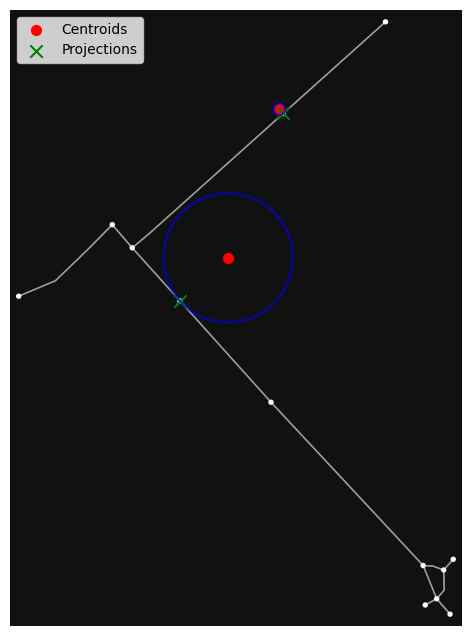

Walking times between H3 cells:
None


In [215]:
from matplotlib.patches import Circle

h3_cell1 = "8b1951234622fff"
h3_cell2 = "8b1951234623fff"

h3_cell1, h3_cell2 = "8b1951234759fff", "8b195123474afff"

h3_cell1 , h3_cell2 = "8b195c058672fff", "8b195c058673fff"

h3_cell1, h3_cell2 = "8b195c058758fff", "8b195c05875bfff"

h3_cell1, h3_cell2 = "8b195c05874efff", "8b195c05874afff"

ors_client = ors.Client(key="eyJvcmciOiI1YjNjZTM1OTc4NTExMTAwMDFjZjYyNDgiLCJpZCI6ImU4MGRmYThhZTVmNzQyYWY4MGZjMTJmZDg4ZjY1ZDNjIiwiaCI6Im11cm11cjY0In0=")
result = walking_times_h3(h3_cell1, h3_cell2, ors_client=ors_client, show_map=True)
print("Walking times between H3 cells:")
print(result)

In [3]:
display(m)

NameError: name 'm' is not defined